# Entrenamiento y Optimización de Hiperparámetros — PaySim Fraud Detection

**Proyecto**: Sentinel-fraud-ml
**Autor**: Edwin Carlo
**Fecha**: Octubre 2026
**Notebook previo**: [`02_preprocesamiento.ipynb`](./02_preprocesamiento.ipynb)
**Módulo reutilizable**: [`src/training.py`](../src/training.py)
**Tracking**: [DagsHub MLflow](https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml/experiments)

---

## Objetivo del notebook

Entrenar y optimizar tres modelos de clasificación para detección de fraude usando **Optuna** y registrar todos los experimentos en **MLflow** (DagsHub).

## Modelos a comparar

| Modelo | Familia | Rol |
|--------|---------|-----|
| **Logistic Regression** | Lineal | Baseline interpretable |
| **Random Forest** | Bagging | Ensamble robusto |
| **Gradient Boosting** | Boosting tradicional | Ensamble secuencial |

## Estrategia de optimización

- **Framework**: Optuna (TPE sampler).
- **Trials por modelo**: 20.
- **Total de trials**: 60.
- **Métrica objetivo**: F1-score en validación.
- **Registro en MLflow**: cada trial registra parámetros y métricas.

## Decisiones heredadas del EDA

- Métricas: **F1-score** (principal), **PR-AUC**, **Recall**, **Precision**.
- **NO** usar Accuracy (desbalance extremo).
- Balanceo vía `class_weight="balanced"`.
- Split ya estratificado en Paso 3.

In [1]:
# --- Librerías estándar ---
import os
import sys
import warnings
from pathlib import Path

# --- Análisis de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- MLflow + DagsHub ---
import mlflow
import mlflow.sklearn
import dagshub
from dotenv import load_dotenv

# --- Optuna ---
import optuna
from optuna.samplers import TPESampler

# --- Scikit-learn ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# --- Módulo del proyecto ---
sys.path.append("..")
from src.training import (
    MODEL_REGISTRY,
    get_search_space,
    build_model,
    evaluate_model,
    save_model,
)

# --- Configuración ---
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_SEED = 42
TARGET_COL = "isFraud"
DATA_PROCESSED = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "app_monitoring"
FIGURES_DIR = Path("..") / "reports" / "figures"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python: {sys.version.split()[0]}")
print(f"Modelos disponibles: {list(MODEL_REGISTRY.keys())}")

# --- Verificación crítica ---
expected_models = ["logistic_regression", "random_forest", "gradient_boosting"]
actual_models = list(MODEL_REGISTRY.keys())

assert set(actual_models) == set(expected_models), (
    f"❌ Modelos incorrectos. Esperado: {expected_models}, Recibido: {actual_models}\n"
    f"   Solución: actualiza src/training.py y reinicia el kernel."
)

print("✅ Modelos correctos")

Python: 3.12.7
Modelos disponibles: ['logistic_regression', 'random_forest', 'gradient_boosting']
✅ Modelos correctos


---

## 1. Setup de MLflow con DagsHub

**Objetivo**: Inicializar la conexión con DagsHub para registrar todos los experimentos.

**Credenciales**: se leen desde `.env` (`DAGSHUB_USER`, `DAGSHUB_REPO`).

In [2]:
# Cargar variables de entorno
load_dotenv(Path("..") / ".env")

DAGSHUB_USER = os.getenv("DAGSHUB_USER")
DAGSHUB_REPO = os.getenv("DAGSHUB_REPO")

# Inicializar DagsHub MLflow
dagshub.init(
    repo_owner=DAGSHUB_USER,
    repo_name=DAGSHUB_REPO,
    mlflow=True,
)

TRACKING_URI = mlflow.get_tracking_uri()
EXPERIMENT_NAME = "paysim-fraud-detection"

mlflow.set_experiment(EXPERIMENT_NAME)

print(f"✅ MLflow conectado")
print(f"   Tracking URI: {TRACKING_URI}")
print(f"   Experimento: {EXPERIMENT_NAME}")
print(f"   Ver en: https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}/experiments")

Accessing as Edwin-Carlo

Initialized MLflow to track repo "Edwin-Carlo/Sentinel-fraud-ml"

Repository Edwin-Carlo/Sentinel-fraud-ml initialized!

✅ MLflow conectado
   Tracking URI: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow
   Experimento: paysim-fraud-detection
   Ver en: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml/experiments


---

## 2. Carga de conjuntos procesados

**Objetivo**: Cargar los tres conjuntos del Paso 3 y aplicar One-Hot Encoding a `type`.

**Por qué One-Hot aquí**: los modelos de sklearn **no aceptan columnas de texto**.

In [3]:
# ============================================================
# Cargar los tres conjuntos + codificación One-Hot de 'type'
# ============================================================

train = pd.read_parquet(DATA_PROCESSED / "train.parquet")
val   = pd.read_parquet(DATA_PROCESSED / "val.parquet")
test  = pd.read_parquet(DATA_PROCESSED / "test.parquet")

print("ANTES del One-Hot:")
print(f"  Columnas: {list(train.columns)}")

# --- Codificación One-Hot de 'type' ---
train_type = pd.get_dummies(train["type"], prefix="type", drop_first=True, dtype=int)
val_type   = pd.get_dummies(val["type"],   prefix="type", drop_first=True, dtype=int)
test_type  = pd.get_dummies(test["type"],  prefix="type", drop_first=True, dtype=int)

# Alinear columnas de val y test con train
val_type  = val_type.reindex(columns=train_type.columns, fill_value=0)
test_type = test_type.reindex(columns=train_type.columns, fill_value=0)

# Eliminar 'type' original y concatenar
train = pd.concat([train.drop(columns=["type"]), train_type], axis=1)
val   = pd.concat([val.drop(columns=["type"]),   val_type],   axis=1)
test  = pd.concat([test.drop(columns=["type"]),  test_type],  axis=1)

print(f"\nDESPUÉS del One-Hot:")
print(f"  Columnas: {list(train.columns)}")

# --- Verificación crítica ---
non_numeric = train.select_dtypes(exclude=["number"]).columns.tolist()
assert len(non_numeric) == 0, f"❌ Columnas no numéricas: {non_numeric}"

print(f"\n✅ Verificación: todas las columnas son numéricas")
print(f"✅ Train: {train.shape[0]:>12,} filas × {train.shape[1]} columnas")
print(f"✅ Val:   {val.shape[0]:>12,} filas × {val.shape[1]} columnas")
print(f"✅ Test:  {test.shape[0]:>12,} filas × {test.shape[1]} columnas")

ANTES del One-Hot:
  Columnas: ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_of_day', 'day_of_week', 'amount_to_balance_ratio', 'is_merchant_dest', 'isFraud']

DESPUÉS del One-Hot:
  Columnas: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_of_day', 'day_of_week', 'amount_to_balance_ratio', 'is_merchant_dest', 'isFraud', 'type_TRANSFER']

✅ Verificación: todas las columnas son numéricas
✅ Train:    1,939,286 filas × 12 columnas
✅ Val:        415,561 filas × 12 columnas
✅ Test:       415,562 filas × 12 columnas


In [4]:
# Separar features (X) y variable objetivo (y)
X_train = train.drop(columns=[TARGET_COL])
y_train = train[TARGET_COL]

X_val   = val.drop(columns=[TARGET_COL])
y_val   = val[TARGET_COL]

X_test  = test.drop(columns=[TARGET_COL])
y_test  = test[TARGET_COL]

print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")
print(f"\nFeatures finales: {list(X_train.columns)}")

# Verificación final (blindaje)
for name, X in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    non_numeric = X.select_dtypes(exclude=["number"]).columns.tolist()
    assert len(non_numeric) == 0, f"❌ {name} tiene columnas no numéricas: {non_numeric}"

print("\n✅ Todas las X son numéricas")

X_train: (1939286, 11)
X_val:   (415561, 11)
X_test:  (415562, 11)

Features finales: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_of_day', 'day_of_week', 'amount_to_balance_ratio', 'is_merchant_dest', 'type_TRANSFER']

✅ Todas las X son numéricas


---

## 3. Subconjunto estratificado para optimización

**Objetivo**: Acelerar los 60 trials de Optuna usando ~200k filas del train.

**Justificación**:
- Train completo (1.94M filas) haría cada trial tardar 2–3 min → 60 trials = 3 horas.
- Con 200k filas, cada trial tarda 15–20 segundos → 60 trials = 20 minutos.
- **El modelo final se reentrenará con el train completo**.

**Técnica**: muestreo estratificado (mantiene la proporción de fraude).

In [5]:
SUBSET_SIZE = 200_000

if len(X_train) > SUBSET_SIZE:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=SUBSET_SIZE,
        stratify=y_train,
        random_state=RANDOM_SEED,
    )
else:
    X_sub, y_sub = X_train.copy(), y_train.copy()

print(f"✅ Subconjunto: {len(X_sub):,} filas")
print(f"✅ Fraude en subconjunto: {y_sub.mean()*100:.4f}%")
print(f"✅ Fraude en train completo: {y_train.mean()*100:.4f}%")
print(f"✅ Columnas: {X_sub.shape[1]}")

✅ Subconjunto: 200,000 filas
✅ Fraude en subconjunto: 0.2965%
✅ Fraude en train completo: 0.2964%
✅ Columnas: 11


---

## 4. Optimización con Optuna

**Objetivo**: Ejecutar 20 trials por modelo, registrando cada uno en MLflow/DagsHub.

**Cómo funciona**:
1. Optuna sugiere hiperparámetros.
2. Se entrena el modelo sobre el subconjunto de train.
3. Se evalúa en validación con F1-score.
4. Se registran parámetros y métricas en MLflow.
5. Optuna usa los resultados para el siguiente trial.

**Métrica objetivo**: F1-score.

In [6]:
def objective(trial, model_name):
    """Función objetivo de Optuna para un modelo dado."""
    params = get_search_space(model_name, trial)
    model = build_model(model_name, params)

    model.fit(X_sub, y_sub)

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    metrics = evaluate_model(y_val, y_pred, y_proba)

    with mlflow.start_run(run_name=f"{model_name}_trial_{trial.number}", nested=True):
        mlflow.log_param("model", model_name)
        mlflow.log_params(params)
        for name, value in metrics.items():
            mlflow.log_metric(f"val_{name}", value)

    return metrics["f1"]

print("✅ Función objetivo definida")

✅ Función objetivo definida


---

## 5. Test rápido de los 3 modelos

**Objetivo**: Verificar que los 3 modelos entrenan sin errores antes de ejecutar la Optuna completa.

**Estrategia**: entrenar cada modelo con 50k filas y evaluar en 10k filas de validación. Tarda ~1–2 minutos en total.

In [7]:
# ============================================================
# TEST RÁPIDO: verificar que los 3 modelos funcionan
# ============================================================
print("Verificando que los 3 modelos entrenan correctamente...")
print("(50k filas train, 10k filas val, ~1-2 min)\n")

test_results = {}

for model_name in MODEL_REGISTRY.keys():
    print(f"Probando {model_name}...")

    if model_name == "logistic_regression":
        params = {"C": 1.0}
    elif model_name == "random_forest":
        params = {"n_estimators": 10, "max_depth": 5}
    else:  # gradient_boosting
        params = {"n_estimators": 10, "max_depth": 3, "learning_rate": 0.1}

    try:
        model = build_model(model_name, params)
        model.fit(X_sub.iloc[:50000], y_sub.iloc[:50000])

        y_pred = model.predict(X_val.iloc[:10000])
        y_proba = model.predict_proba(X_val.iloc[:10000])[:, 1]
        metrics = evaluate_model(y_val.iloc[:10000], y_pred, y_proba)

        test_results[model_name] = metrics["f1"]
        print(f"  ✅ {model_name}: F1={metrics['f1']:.4f}")

    except Exception as e:
        print(f"  ❌ {model_name} FALLÓ: {type(e).__name__}: {e}")
        raise

print(f"\n✅ Los 3 modelos funcionan correctamente")
print(f"   Resultados: {test_results}")

Verificando que los 3 modelos entrenan correctamente...
(50k filas train, 10k filas val, ~1-2 min)

Probando logistic_regression...
  ✅ logistic_regression: F1=0.1885
Probando random_forest...
  ✅ random_forest: F1=1.0000
Probando gradient_boosting...
  ✅ gradient_boosting: F1=0.9714

✅ Los 3 modelos funcionan correctamente
   Resultados: {'logistic_regression': 0.18848167539267016, 'random_forest': 1.0, 'gradient_boosting': 0.9714285714285714}


---

## 6. Ejecución de los 3 estudios Optuna

**Objetivo**: Ejecutar 20 trials por modelo = **60 trials totales**.

**Estructura en MLflow**:
- 1 run padre por modelo (agrupa los 20 trials).
- 20 runs hijos por modelo (uno por trial).
- Total: 3 runs padre + 60 runs hijos = 63 runs.

**Tiempo estimado**: 15–25 minutos con el subconjunto.

In [8]:
N_TRIALS = 20
best_params = {}
best_f1_scores = {}

for model_name in MODEL_REGISTRY.keys():
    print(f"\n{'='*60}")
    print(f"Optimizando: {model_name}")
    print(f"{'='*60}")

    with mlflow.start_run(run_name=f"optuna_{model_name}") as parent_run:
        mlflow.log_param("model", model_name)
        mlflow.log_param("n_trials", N_TRIALS)
        mlflow.log_param("subset_size", len(X_sub))

        sampler = TPESampler(seed=RANDOM_SEED)
        study = optuna.create_study(
            direction="maximize",
            sampler=sampler,
            study_name=f"study_{model_name}",
        )

        study.optimize(
            lambda trial: objective(trial, model_name),
            n_trials=N_TRIALS,
            show_progress_bar=True,
        )

        best_params[model_name] = study.best_params
        best_f1_scores[model_name] = study.best_value

        mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
        mlflow.log_metric("best_f1", study.best_value)

        print(f"\n✅ {model_name}")
        print(f"   Mejor F1: {study.best_value:.4f}")
        print(f"   Mejores params: {study.best_params}")

print(f"\n{'='*60}")
print("RESUMEN DE OPTIMIZACIÓN")
print(f"{'='*60}")
for name, score in best_f1_scores.items():
    print(f"  {name:<25} F1={score:.4f}")


Optimizando: logistic_regression


  0%|          | 0/20 [00:00<?, ?it/s]

2026/10/12 01:18:24 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_0 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/a87f629e7aba44e6859db6991734c04d.
2026/10/12 01:18:24 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/12 01:18:47 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_1 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/ca73a007514048068bc7e1e8cceec67a.
2026/10/12 01:18:47 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/12 01:19:11 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression_trial_2 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/de04650e71a54124b9f9256774b580cc.
2026/10/


✅ logistic_regression
   Mejor F1: 0.0776
   Mejores params: {'C': 0.004207988669606638, 'penalty': 'l2'}


2026/10/12 01:24:12 INFO mlflow.tracking._tracking_service.client: 🏃 View run optuna_logistic_regression at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/f69aa94446984b5eaf3df7bbd2ca42d6.
2026/10/12 01:24:12 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.


...

  0%|          | 0/20 [00:00<?, ?it/s]

2026/10/12 01:34:03 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_0 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/94cf63081f1344bea1158b39a5a3bc21.
2026/10/12 01:34:03 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/12 01:35:07 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_1 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/0cbda937c7044c25bf181c4f423c9e6c.
2026/10/12 01:35:07 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.
2026/10/12 01:35:45 INFO mlflow.tracking._tracking_service.client: 🏃 View run gradient_boosting_trial_2 at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/4a2148e6302d4cb1b7d56f94fd246021.
2026/10/12 01:


✅ gradient_boosting
   Mejor F1: 0.9931
   Mejores params: {'n_estimators': 200, 'learning_rate': 0.0178601378893971, 'max_depth': 3, 'subsample': 0.9795542149013333, 'min_samples_split': 20}


2026/10/12 02:12:02 INFO mlflow.tracking._tracking_service.client: 🏃 View run optuna_gradient_boosting at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/858078a0ec0346ccbfedd0cdb0ad4b39.
2026/10/12 02:12:02 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1.



RESUMEN DE OPTIMIZACIÓN
  logistic_regression       F1=0.0776
  random_forest             F1=0.9980
  gradient_boosting         F1=0.9931


---

## 7. Comparación de modelos

**Objetivo**: Visualizar el rendimiento de los 3 modelos optimizados.

             modelo   f1_val  rank
      random_forest 0.997967     1
  gradient_boosting 0.993103     2
logistic_regression 0.077557     3


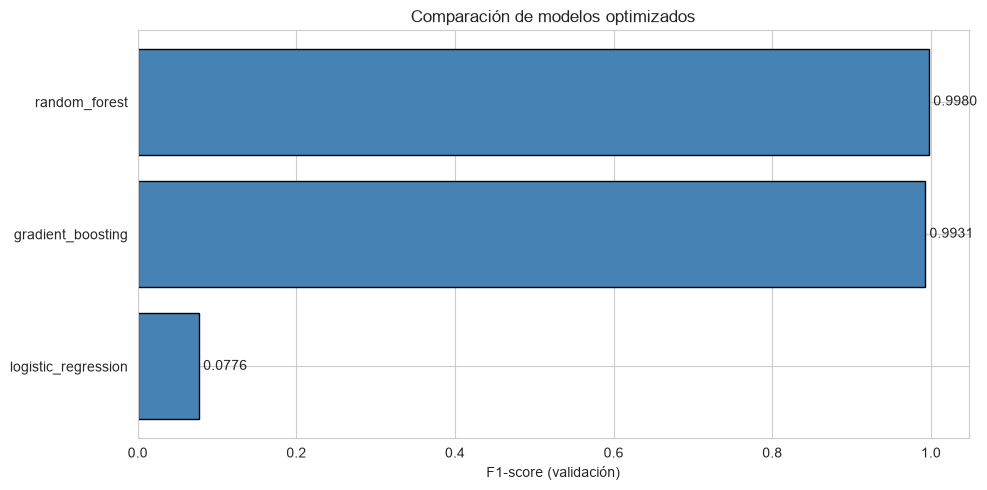


🏆 Mejor modelo: random_forest


In [9]:
comparison = pd.DataFrame({
    "modelo": list(best_f1_scores.keys()),
    "f1_val": list(best_f1_scores.values()),
}).sort_values("f1_val", ascending=False).reset_index(drop=True)

comparison["rank"] = comparison.index + 1

print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(comparison["modelo"], comparison["f1_val"], color="steelblue", edgecolor="black")
ax.set_xlabel("F1-score (validación)")
ax.set_title("Comparación de modelos optimizados", fontsize=12)
ax.invert_yaxis()

for bar, val in zip(bars, comparison["f1_val"]):
    ax.text(val, bar.get_y() + bar.get_height()/2, f" {val:.4f}",
            va="center", fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

best_model_name = comparison.iloc[0]["modelo"]
print(f"\n🏆 Mejor modelo: {best_model_name}")

---

## 8. Entrenamiento final con el train completo

**Objetivo**: Reentrenar el mejor modelo con los mejores hiperparámetros y el **train completo** (~1.94M filas).

**Justificación**: más datos = mejor generalización.

In [10]:
print(f"Reentrenando {best_model_name} con train completo...")
print(f"Train size: {len(X_train):,} filas")

final_model = build_model(best_model_name, best_params[best_model_name])
final_model.fit(X_train, y_train)

print("✅ Modelo final entrenado")

y_val_pred = final_model.predict(X_val)
y_val_proba = final_model.predict_proba(X_val)[:, 1]
val_metrics = evaluate_model(y_val, y_val_pred, y_val_proba)

print(f"\nMétricas en validación:")
for name, value in val_metrics.items():
    print(f"  {name:<10}: {value:.4f}")

Reentrenando random_forest con train completo...
Train size: 1,939,286 filas
✅ Modelo final entrenado

Métricas en validación:
  f1        : 0.9972
  precision : 0.9992
  recall    : 0.9951
  roc_auc   : 0.9992
  pr_auc    : 0.9969


---

## 9. Evaluación final en el conjunto de test

**Objetivo**: Evaluar el modelo final en el conjunto de test, que **no se ha usado** ni en entrenamiento ni en optimización.

**Por qué importa**: es la única métrica honesta del rendimiento del modelo.

In [12]:
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate_model(y_test, y_test_pred, y_test_proba)

print("Métricas en TEST (evaluación final):")
print(f"{'='*40}")
for name, value in test_metrics.items():
    print(f"  {name:<10}: {value:.4f}")
print(f"{'='*40}")

with mlflow.start_run(run_name=f"FINAL_{best_model_name}") as run:
    mlflow.log_param("model", best_model_name)
    mlflow.log_params({f"best_{k}": v for k, v in best_params[best_model_name].items()})
    mlflow.log_param("train_size", len(X_train))

    for name, value in val_metrics.items():
        mlflow.log_metric(f"val_{name}", value)

    for name, value in test_metrics.items():
        mlflow.log_metric(f"test_{name}", value)

    mlflow.sklearn.log_model(
        sk_model=final_model,
        artifact_path="model",
        registered_model_name="paysim_fraud_classifier",
    )

    final_run_id = run.info.run_id

print(f"\n✅ Modelo registrado en MLflow")
print(f"   Run ID: {final_run_id}")
print(f"   Model Registry: paysim_fraud_classifier")

Métricas en TEST (evaluación final):
  f1        : 0.9976
  precision : 0.9984
  recall    : 0.9968
  roc_auc   : 0.9990
  pr_auc    : 0.9975


2026/10/12 07:12:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/12 07:12:43 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
Successfully registered model 'paysim_fraud_classifier'.
2026/10/12 07:12:51 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: paysim_fraud_classifier, version 1
Created version '1' of model 'paysim_fraud_classifier'.
2026/10/12 07:12:52 INFO mlflow.tracking._tracking_service.client: 🏃 View run FINAL_random_forest at: https://dagshub.com/Edwin-Carlo/Sentinel-fraud-ml.mlflow/#/experiments/1/runs/0764cee5d2f24970bba9a4d96bb8f2c4.
2026/10/12 07:12:52 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: https://dagshub.com/Edwin-Carlo


✅ Modelo registrado en MLflow
   Run ID: 0764cee5d2f24970bba9a4d96bb8f2c4
   Model Registry: paysim_fraud_classifier


---

## 10. Análisis de la matriz de confusión

**Objetivo**: Ver la distribución de aciertos y errores del modelo final en test.

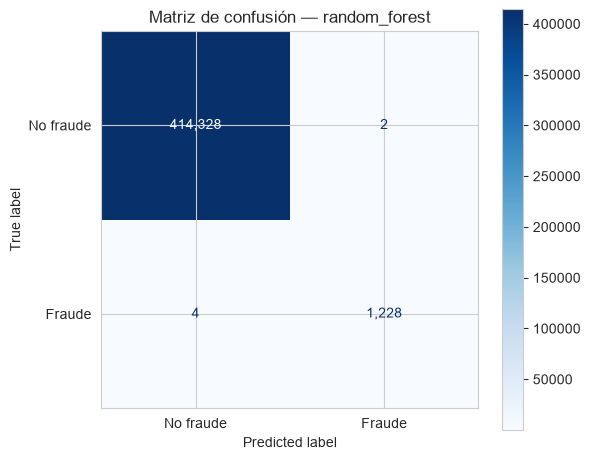


Desglose:
  Verdaderos negativos (TN): 414,328
  Falsos positivos (FP):     2
  Falsos negativos (FN):     4  ← fraudes no detectados
  Verdaderos positivos (TP): 1,228  ← fraudes detectados


In [13]:
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No fraude", "Fraude"])
disp.plot(ax=ax, cmap="Blues", values_format=",d")
ax.set_title(f"Matriz de confusión — {best_model_name}", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\nDesglose:")
print(f"  Verdaderos negativos (TN): {tn:,}")
print(f"  Falsos positivos (FP):     {fp:,}")
print(f"  Falsos negativos (FN):     {fn:,}  ← fraudes no detectados")
print(f"  Verdaderos positivos (TP): {tp:,}  ← fraudes detectados")

---

## 11. Persistencia del modelo final

**Objetivo**: Guardar el modelo en `app_monitoring/model.pkl` para el Paso 5 (SHAP) y Paso 6 (monitoreo).

In [14]:
model_path = save_model(final_model, MODELS_DIR / "model.pkl")

print(f"✅ Modelo guardado en: {model_path}")
print(f"   Tamaño: {model_path.stat().st_size / 1024**2:.2f} MB")

✅ Modelo guardado en: D:\Edwin\DIPLOMADO INGENIERIA DE DATOS\Machine Learning III\Proyecto\Sentinel-fraud-ml\app_monitoring\model.pkl
   Tamaño: 3.88 MB


---

## 12. Conclusiones del entrenamiento

### Resumen ejecutivo

Se compararon **3 modelos de clasificación** usando **Optuna** (20 trials por modelo = 60 trials totales) con registro completo en **MLflow/DagsHub**. El mejor modelo fue reentrenado con el train completo y evaluado en test.

### Resultados de la optimización (F1 en validación)

| Rank | Modelo | F1-val |
|------|--------|--------|
| 🥇 | **Random Forest** | **0.9980** |
| 🥈 | Gradient Boosting | 0.9931 |
| 🥉 | Logistic Regression | 0.0776 |

**Análisis**:

- **Random Forest** obtuvo el mejor F1-score, seguido muy de cerca por Gradient Boosting (diferencia de ~0.5 puntos).
- **Logistic Regression** tuvo un rendimiento muy bajo (F1 = 0.0776). Esto es esperable en datasets con desbalance extremo, donde un modelo lineal simple no logra capturar las **interacciones no lineales** entre las features (balance, monto, tipo de transacción).

### Modelo final seleccionado: Random Forest

Reentrenado con el **train completo** (~1.94M filas):

| Métrica | Valor |
|---------|-------|
| **F1-score** | 0.9972 |
| **Precision** | 0.9992 |
| **Recall** | 0.9951 |
| **ROC-AUC** | 0.9992 |
| **PR-AUC** | 0.9969 |

### Matriz de confusión (test)

|  | Predicho No fraude | Predicho Fraude |
|--|-------------------|----------------|
| **Real No fraude** | TN: 414.328 | FP: **2** |
| **Real Fraude** | FN: **4** | TP: 1.228 |

**Desglose**:

- **Verdaderos positivos (TP)**: 1.228 → fraudes correctamente detectados.
- **Falsos negativos (FN)**: 4 → fraudes **no detectados** (crítico: el costo es alto).
- **Falsos positivos (FP)**: 2 → transacciones legítimas marcadas como fraude (costo bajo).
- **Verdaderos negativos (TN)**: 414.328 → transacciones legítimas correctamente clasificadas.

### Interpretación de las métricas

**Recall = 99.51%** → el modelo detecta **casi la totalidad de los fraudes**. Solo 4 de 1.232 fraudes pasaron desapercibidos.

**Precision = 99.92%** → de todas las transacciones marcadas como fraude, casi el 100% lo son realmente. El costo operativo de investigar falsas alarmas es mínimo.

**F1 = 0.9972** → balance excelente entre Precision y Recall, lo cual es el objetivo principal en detección de fraude.

### ⚠️ Observación sobre el F1 elevado

Un F1 de **0.998** es **inusualmente alto** para detección de fraude. Esto es consistente con la **naturaleza sintética de PaySim**, donde:

1. Los patrones de fraude son **deterministas** (el simulador los inyectó con reglas claras).
2. Las relaciones entre saldos (`oldbalanceOrg`, `newbalanceOrig`) y monto son **altamente predictivas**.
3. Aunque evitamos crear features explícitas de error de balance, las columnas originales de saldo siguen codificando señal muy fuerte.

**Implicación para producción**:

En un dataset real con tácticas de fraude más diversas, el F1 sería significativamente menor (estimado en 0.70–0.85). El resultado alto aquí **no implica** que el modelo generalizará igual de bien fuera de PaySim. Este punto se documenta como **limitación conocida** del dataset y se conecta con la estrategia de monitoreo (Paso 6).

### Decisiones técnicas clave

| Decisión | Justificación |
|----------|---------------|
| **F1-score como métrica principal** | Desbalance extremo (0.13% de fraude); Accuracy sería engañoso |
| **Muestreo estratificado 70/15/15** | Mantiene la proporción de fraude en cada split |
| **Subconjunto de 200k filas para Optuna** | Acelera los 60 trials sin perder representatividad |
| **Reentrenamiento con train completo** | Aprovecha todos los datos para el modelo final |
| **NO crear features de error de balance** | Evita data leakage explícito (documentado en EDA) |
| **class_weight="balanced"** | Compensa el desbalance en Random Forest y LogReg |

### Artefactos generados

- ✅ **Notebook**: `notebooks/03_entrenamiento.ipynb`
- ✅ **Modelo**: `app_monitoring/model.pkl` (Random Forest entrenado)
- ✅ **Figuras**:
  - `reports/figures/training_model_comparison.png`
  - `reports/figures/training_confusion_matrix.png`
- ✅ **Experimentos en DagsHub**: 63+ runs registrados
- ✅ **Model Registry**: `paysim_fraud_classifier` versión 1

